In [1]:
# CELL 1: PROJECT INITIALIZATION

import os
import json
import gc
import time
import uuid
import shutil
import zipfile
import re
import warnings

from pathlib import Path
from datetime import datetime

warnings.filterwarnings("ignore")

PROJECT_NAME = "STEEL_INVOICE_QWEN_V1"
MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

BASE_DIR = Path("/content/steel_invoice_project")
INPUT_DIR = BASE_DIR / "input"
WORK_DIR = BASE_DIR / "working"
OUTPUT_DIR = BASE_DIR / "output"

for folder in [INPUT_DIR, WORK_DIR, OUTPUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_DIR = OUTPUT_DIR / f"STEEL_INVOICE_{RUN_ID}"

RUN_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT:", PROJECT_NAME)
print("MODEL:", MODEL_ID)
print("RUN ID:", RUN_ID)
print("PROJECT DIRECTORY:", BASE_DIR)

PROJECT: STEEL_INVOICE_QWEN_V1
MODEL: Qwen/Qwen2.5-VL-3B-Instruct
RUN ID: 20261106_052348
PROJECT DIRECTORY: /content/steel_invoice_project


In [2]:
# CELL 2: HARDWARE VALIDATION

import torch
import psutil

print("PyTorch:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

ram = psutil.virtual_memory()

print("System RAM:", round(ram.total / 1024**3, 2), "GB")
print("Available RAM:", round(ram.available / 1024**3, 2), "GB")

if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU detected. Go to Runtime > Change runtime type "
        "and select a GPU runtime if available."
    )

GPU_NAME = torch.cuda.get_device_name(0)
GPU_MEMORY = torch.cuda.get_device_properties(0).total_memory / 1024**3

print("GPU:", GPU_NAME)
print("GPU Memory:", round(GPU_MEMORY, 2), "GB")

if GPU_MEMORY < 8:
    raise RuntimeError(
        "This notebook's recommended configuration needs "
        "a GPU with at least 8 GB VRAM."
    )

print("Hardware validation completed.")

PyTorch: 2.11.0+cu130
CUDA Available: True
System RAM: 12.67 GB
Available RAM: 11.14 GB
GPU: Tesla T4
GPU Memory: 14.56 GB
Hardware validation completed.


In [3]:
# CELL 3: INSTALL DEPENDENCIES

%pip install -q --upgrade pip

%pip install -q \
    git+https://github.com/huggingface/transformers \
    accelerate \
    bitsandbytes \
    qwen-vl-utils \
    pymupdf \
    pillow \
    pandas \
    numpy \
    openpyxl \
    jsonschema \
    matplotlib \
    tqdm

print("Dependencies installed.")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Dependencies installed.


In [4]:
# CELL 4: IMPORT LIBRARIES

import pandas as pd
import numpy as np

from PIL import (
    Image,
    ImageOps,
    ImageEnhance,
    ImageFilter
)

from google.colab import files

from tqdm.auto import tqdm

from IPython.display import display

from transformers import (
    AutoProcessor,
    Qwen2_5_VLForConditionalGeneration,
    BitsAndBytesConfig
)

from qwen_vl_utils import process_vision_info

from decimal import Decimal, InvalidOperation

print("All libraries imported successfully.")

All libraries imported successfully.


In [5]:
# CELL 5: LOAD QWEN2.5-VL-3B

torch.cuda.empty_cache()
gc.collect()

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

print("Downloading Qwen processor...")

processor = AutoProcessor.from_pretrained(
    MODEL_ID,
    min_pixels=256 * 28 * 28,
    max_pixels=1280 * 28 * 28
)

print("Downloading and loading Qwen model...")

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    device_map="auto",
    torch_dtype=torch.float16,
    attn_implementation="sdpa",
    low_cpu_mem_usage=True
)

model.eval()

print("\nQwen Vision loaded successfully.")

print("Model:", MODEL_ID)
print("Quantization: 4-bit NF4")
print("Device:", model.device)
print("GPU Memory Used:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

... (3 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]


Qwen Vision loaded successfully.
Model: Qwen/Qwen2.5-VL-3B-Instruct
Quantization: 4-bit NF4
Device: cuda:0
GPU Memory Used: 2.25 GB


In [6]:
# CELL 6: VISION MODEL TEST

from PIL import Image, ImageDraw

test_image = Image.new("RGB", (900, 500), "white")
draw = ImageDraw.Draw(test_image)

draw.text((40, 40), "STEEL INVOICE TEST", fill="black")
draw.text((40, 130), "Product: Hot Rolled Coil", fill="black")
draw.text((40, 190), "Grade: IS 2062 E250", fill="black")
draw.text((40, 250), "Quantity: 10 MT", fill="black")
draw.text((40, 310), "Rate: 55000 INR / MT", fill="black")

test_path = WORK_DIR / "qwen_vision_test.png"
test_image.save(test_path)

messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": str(test_path)
            },
            {
                "type": "text",
                "text": "Describe the steel product and its quantity."
            }
        ]
    }
]

text_input = processor.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

image_inputs, video_inputs = process_vision_info(messages)

inputs = processor(
    text=[text_input],
    images=image_inputs,
    videos=video_inputs,
    padding=True,
    return_tensors="pt"
).to(model.device)

with torch.inference_mode():
    output_ids = model.generate(
        **inputs,
        max_new_tokens=150,
        do_sample=False
    )

generated = output_ids[:, inputs.input_ids.shape[1]:]

test_output = processor.batch_decode(
    generated,
    skip_special_tokens=True
)[0]

print(test_output)

The steel product is Hot Rolled Coil, and the quantity is 10 MT (metric tons).


In [55]:
# CELL 7: SINGLE INVOICE UPLOAD

uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError(
        "Upload exactly ONE invoice file per execution."
    )

filename = list(uploaded.keys())[0]

allowed_extensions = [
    ".jpg", ".jpeg", ".png", ".pdf"
]

extension = Path(filename).suffix.lower()

if extension not in allowed_extensions:
    raise ValueError("Unsupported invoice format.")

SOURCE_FILE = INPUT_DIR / filename

with open(SOURCE_FILE, "wb") as f:
    f.write(uploaded[filename])

print("Uploaded:", filename)
print("File size:", round(SOURCE_FILE.stat().st_size / 1024, 2), "KB")
print("Saved at:", SOURCE_FILE)

Saving ChatGPT Image Nov 2, 2026, 01_43_25 PM.jpg to ChatGPT Image Nov 2, 2026, 01_43_25 PM (1).jpg
Uploaded: ChatGPT Image Nov 2, 2026, 01_43_25 PM (1).jpg
File size: 440.83 KB
Saved at: /content/steel_invoice_project/input/ChatGPT Image Nov 2, 2026, 01_43_25 PM (1).jpg


In [56]:
# CELL 8: PDF / IMAGE CONVERSION

import fitz

PAGE_IMAGES = []

if extension == ".pdf":

    pdf = fitz.open(SOURCE_FILE)

    for page_number, page in enumerate(pdf, start=1):

        pix = page.get_pixmap(
            matrix=fitz.Matrix(220/72, 220/72),
            alpha=False
        )

        image_path = WORK_DIR / f"page_{page_number:03d}.png"

        pix.save(str(image_path))

        PAGE_IMAGES.append({
            "page_number": page_number,
            "image_path": image_path
        })

    pdf.close()

else:

    image_path = WORK_DIR / "page_001.png"

    img = Image.open(SOURCE_FILE).convert("RGB")
    img = ImageOps.exif_transpose(img)
    img.save(image_path)

    PAGE_IMAGES.append({
        "page_number": 1,
        "image_path": image_path
    })

print("Total pages:", len(PAGE_IMAGES))

for page in PAGE_IMAGES:
    print(page)

Total pages: 1
{'page_number': 1, 'image_path': PosixPath('/content/steel_invoice_project/working/page_001.png')}


PAGE: 1 | SIZE: (1536, 1073)


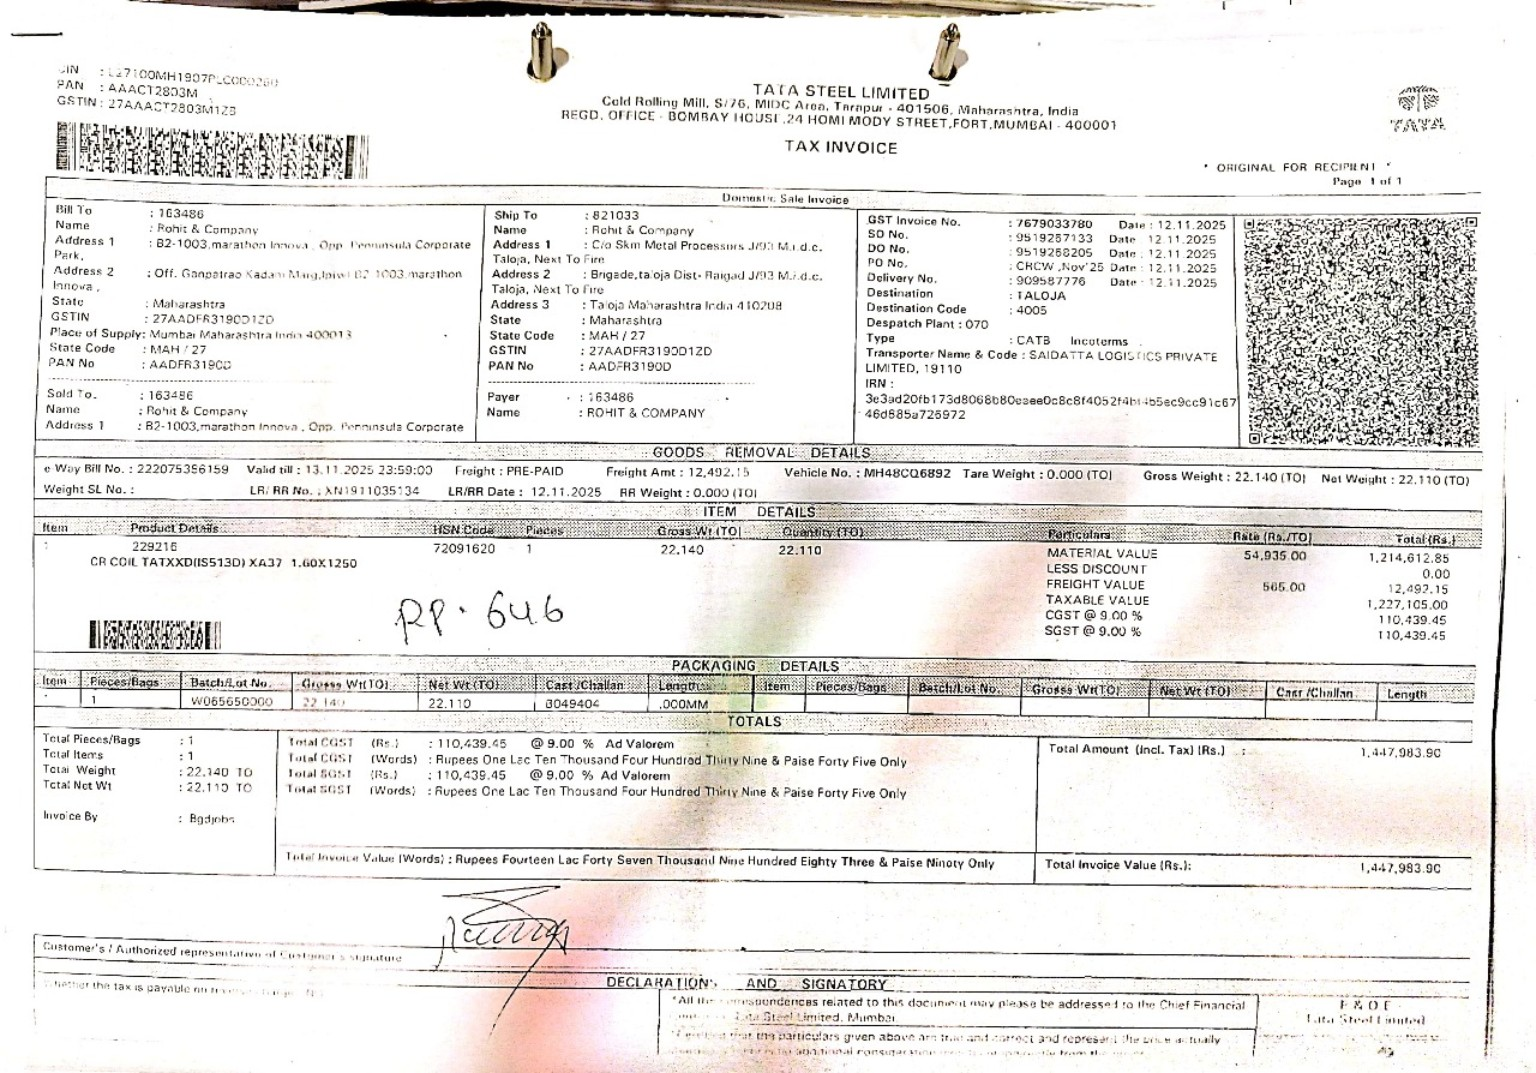

In [57]:
# CELL 9: INVOICE PREVIEW

for page in PAGE_IMAGES:

    img = Image.open(page["image_path"])

    print(
        "PAGE:", page["page_number"],
        "| SIZE:", img.size
    )

    display(img)

In [58]:
# CELL 10: IMAGE ENHANCEMENT

ENHANCED_PAGES = []

for page in PAGE_IMAGES:

    image = Image.open(
        page["image_path"]
    ).convert("RGB")

    image = ImageOps.autocontrast(image, cutoff=1)

    image = ImageEnhance.Contrast(
        image
    ).enhance(1.15)

    image = ImageEnhance.Sharpness(
        image
    ).enhance(1.25)

    enhanced_path = WORK_DIR / (
        f"enhanced_page_{page['page_number']:03d}.png"
    )

    image.save(enhanced_path)

    ENHANCED_PAGES.append({
        "page_number": page["page_number"],
        "image_path": enhanced_path
    })

    print("Enhanced page:", page["page_number"])

Enhanced page: 1


Enhanced page: 1


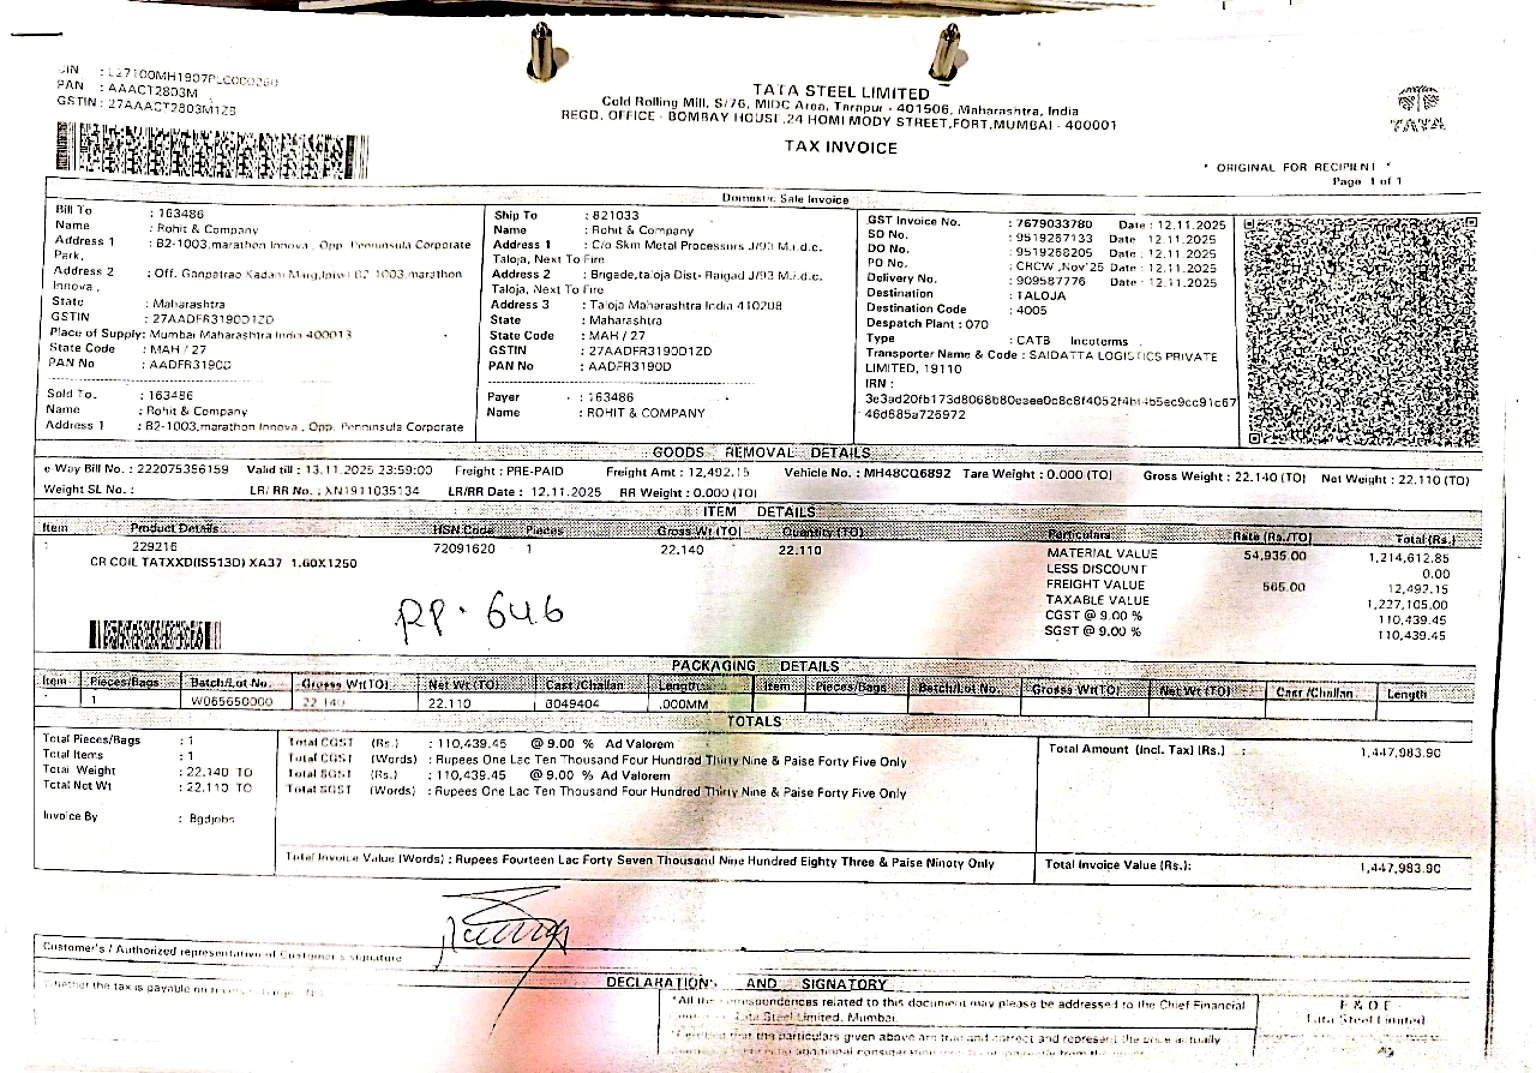

In [59]:
# CELL 11: ENHANCED IMAGE DISPLAY

for page in ENHANCED_PAGES:

    img = Image.open(page["image_path"])

    print("Enhanced page:", page["page_number"])

    display(img)

In [60]:
# CELL 12: CANONICAL INVOICE SCHEMA

CANONICAL_TEMPLATE = {
    "invoice_header": {
        "invoice_number": None,
        "invoice_date": None,
        "supplier_name": None,
        "supplier_gstin": None,
        "supplier_address": None,
        "buyer_name": None,
        "buyer_gstin": None,
        "buyer_address": None,
        "place_of_supply": None,
        "po_number": None,
        "challan_number": None,
        "vehicle_number": None,
        "currency": "INR"
    },

    "items": [],

    "other_charges": [],

    "tax_summary": {
        "taxable_value": None,
        "cgst_amount": None,
        "sgst_amount": None,
        "igst_amount": None,
        "cess_amount": None,
        "total_tax": None
    },

    "totals": {
        "subtotal": None,
        "discount": None,
        "freight": None,
        "round_off": None,
        "grand_total": None,
        "amount_in_words": None
    },

    "document_observations": [],
    "review_flags": []
}

ITEM_TEMPLATE = {
    "line_number": None,
    "raw_description": None,
    "product_family": None,
    "product_form": None,
    "material_code": None,
    "steel_standard": None,
    "grade": None,
    "thickness_mm": None,
    "width_mm": None,
    "length_mm": None,
    "quantity": None,
    "quantity_unit": None,
    "pieces": None,
    "net_weight_mt": None,
    "gross_weight_mt": None,
    "billed_weight_mt": None,
    "rate": None,
    "rate_unit": None,
    "hsn_sac": None,
    "gst_rate": None,
    "taxable_amount": None,
    "cgst_amount": None,
    "sgst_amount": None,
    "igst_amount": None,
    "line_total": None,
    "evidence": None,
    "needs_review": False
}

print(json.dumps(CANONICAL_TEMPLATE, indent=2))

{
  "invoice_header": {
    "invoice_number": null,
    "invoice_date": null,
    "supplier_name": null,
    "supplier_gstin": null,
    "supplier_address": null,
    "buyer_name": null,
    "buyer_gstin": null,
    "buyer_address": null,
    "place_of_supply": null,
    "po_number": null,
    "challan_number": null,
    "vehicle_number": null,
    "currency": "INR"
  },
  "items": [],
  "other_charges": [],
  "tax_summary": {
    "taxable_value": null,
    "cgst_amount": null,
    "sgst_amount": null,
    "igst_amount": null,
    "cess_amount": null,
    "total_tax": null
  },
  "totals": {
    "subtotal": null,
    "discount": null,
    "freight": null,
    "round_off": null,
    "grand_total": null,
    "amount_in_words": null
  },
  "document_observations": [],
  "review_flags": []
}


In [61]:
# CELL 13: STEEL DOMAIN EXTRACTION PROMPT

STEEL_INVOICE_PROMPT = """
You are an expert steel industry invoice document extraction system.

Analyze the supplied invoice image carefully.

TASK:
Extract every visible invoice header, steel product line item,
quantity, weight, rate, HSN, GST and financial amount.

STRICT RULES:

1. Return valid JSON only.
2. Do not return Markdown or explanations outside JSON.
3. Never invent missing values.
4. Use null for unavailable or unreadable information.
5. Preserve the original description exactly in raw_description.
6. Separate steel grade, dimensions, quantity and weight.
7. Do not confuse pieces with metric tonnes.
8. Do not confuse billed weight with net weight.
9. Do not assume quantity and weight are identical.
10. Do not assume a steel grade from a product family.
11. Preserve decimal precision.
12. Preserve invoice numbers and GSTIN characters exactly.
13. Do not calculate missing invoice values.
14. Do not merge two different product rows.
15. Include every visible product row.
16. Identify ambiguous values in review_flags.
17. Record a short supporting visual evidence description.
18. Use the current page number in evidence.

STEEL TERMINOLOGY:

Product families may include:
HRC, CRC, CRCA, CRNO, GP, GC, GI, GL, SS,
MS PLATE, HR PLATE, ANGLE, CHANNEL, BEAM,
TMT, ROUND BAR, FLAT BAR, PIPE, TUBE and COIL.

Recognize:
IS standards, ASTM standards, EN standards,
API standards and JIS standards.

Dimensions:
Thickness in mm.
Width in mm.
Length in mm.

Weight:
kg, MT, tonne, ton and metric tonne.

Units must be retained as printed.

RETURN THIS JSON STRUCTURE:

{
  "invoice_header": {
    "invoice_number": null,
    "invoice_date": null,
    "supplier_name": null,
    "supplier_gstin": null,
    "supplier_address": null,
    "buyer_name": null,
    "buyer_gstin": null,
    "buyer_address": null,
    "place_of_supply": null,
    "po_number": null,
    "challan_number": null,
    "vehicle_number": null,
    "currency": "INR"
  },

  "items": [
    {
      "line_number": null,
      "raw_description": null,
      "product_family": null,
      "product_form": null,
      "material_code": null,
      "steel_standard": null,
      "grade": null,
      "thickness_mm": null,
      "width_mm": null,
      "length_mm": null,
      "quantity": null,
      "quantity_unit": null,
      "pieces": null,
      "net_weight_mt": null,
      "gross_weight_mt": null,
      "billed_weight_mt": null,
      "rate": null,
      "rate_unit": null,
      "hsn_sac": null,
      "gst_rate": null,
      "taxable_amount": null,
      "cgst_amount": null,
      "sgst_amount": null,
      "igst_amount": null,
      "line_total": null,
      "evidence": null,
      "needs_review": false
    }
  ],

  "other_charges": [],

  "tax_summary": {
    "taxable_value": null,
    "cgst_amount": null,
    "sgst_amount": null,
    "igst_amount": null,
    "cess_amount": null,
    "total_tax": null
  },

  "totals": {
    "subtotal": null,
    "discount": null,
    "freight": null,
    "round_off": null,
    "grand_total": null,
    "amount_in_words": null
  },

  "document_observations": [],
  "review_flags": []
}

For evidence, mention the visible label, description or
table-row location supporting the extracted value.

If a value is unclear, do not guess it.
"""

In [62]:
# CELL 14: DIRECT IMAGE EXTRACTION ENGINE

def run_qwen_vision(image_path, page_number):

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": str(image_path)
                },
                {
                    "type": "text",
                    "text": (
                        STEEL_INVOICE_PROMPT
                        + f"\nCURRENT PAGE NUMBER: {page_number}"
                    )
                }
            ]
        }
    ]

    prompt_text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[prompt_text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    start = time.time()

    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=2200,
            do_sample=False,
            repetition_penalty=1.05
        )

    generated_ids_trimmed = [
        output_ids[len(input_ids):]
        for input_ids, output_ids in zip(
            inputs.input_ids,
            generated_ids
        )
    ]

    response = processor.batch_decode(
        generated_ids_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0]

    elapsed = time.time() - start

    del inputs, generated_ids, generated_ids_trimmed
    torch.cuda.empty_cache()

    return {
        "page_number": page_number,
        "raw_response": response,
        "processing_seconds": round(elapsed, 2)
    }


print("Direct Qwen Vision engine ready.")

Direct Qwen Vision engine ready.


In [63]:
# CELL 15: PAGE-WISE EXTRACTION

def parse_json_response(raw_text):

    cleaned = raw_text.strip()

    cleaned = re.sub(
        r"^```(?:json)?\s*",
        "",
        cleaned,
        flags=re.IGNORECASE
    )

    cleaned = re.sub(r"\s*```$", "", cleaned)

    try:
        return json.loads(cleaned)

    except json.JSONDecodeError:

        start = cleaned.find("{")
        end = cleaned.rfind("}")

        if start == -1 or end == -1:
            raise ValueError("No JSON object found.")

        return json.loads(cleaned[start:end+1])


PAGE_RESULTS = []
PAGE_ERRORS = []

for page in tqdm(ENHANCED_PAGES):

    try:

        result = run_qwen_vision(
            page["image_path"],
            page["page_number"]
        )

        result["parsed_json"] = parse_json_response(
            result["raw_response"]
        )

        PAGE_RESULTS.append(result)

        print(
            "Page",
            page["page_number"],
            "completed in",
            result["processing_seconds"],
            "seconds"
        )

    except Exception as e:

        PAGE_ERRORS.append({
            "page_number": page["page_number"],
            "error": str(e)
        })

        print("Page failed:", page["page_number"], str(e))

print("\nSuccessful pages:", len(PAGE_RESULTS))
print("Failed pages:", len(PAGE_ERRORS))

  0%|          | 0/1 [00:00<?, ?it/s]

Page 1 completed in 65.4 seconds

Successful pages: 1
Failed pages: 0


In [64]:
# CELL 16: CANONICAL INVOICE ASSEMBLY

import copy

CANONICAL_INVOICE = copy.deepcopy(CANONICAL_TEMPLATE)

HEADER_FIELDS = list(
    CANONICAL_INVOICE["invoice_header"].keys()
)

for result in PAGE_RESULTS:

    data = result["parsed_json"]
    page_number = result["page_number"]

    header = data.get("invoice_header", {})

    for field in HEADER_FIELDS:

        existing = CANONICAL_INVOICE["invoice_header"].get(field)
        incoming = header.get(field)

        if existing is None and incoming is not None:
            CANONICAL_INVOICE["invoice_header"][field] = incoming

    for item in data.get("items", []):

        normalized_item = copy.deepcopy(ITEM_TEMPLATE)

        for key in normalized_item:
            if key in item:
                normalized_item[key] = item[key]

        normalized_item["source_page"] = page_number

        CANONICAL_INVOICE["items"].append(normalized_item)

    for charge in data.get("other_charges", []):
        CANONICAL_INVOICE["other_charges"].append(charge)

    for key in CANONICAL_INVOICE["tax_summary"]:
        incoming = data.get("tax_summary", {}).get(key)

        if CANONICAL_INVOICE["tax_summary"][key] is None:
            CANONICAL_INVOICE["tax_summary"][key] = incoming

    for key in CANONICAL_INVOICE["totals"]:
        incoming = data.get("totals", {}).get(key)

        if CANONICAL_INVOICE["totals"][key] is None:
            CANONICAL_INVOICE["totals"][key] = incoming

    CANONICAL_INVOICE["document_observations"].extend(
        data.get("document_observations", [])
    )

    CANONICAL_INVOICE["review_flags"].extend(
        data.get("review_flags", [])
    )

CANONICAL_INVOICE["page_count"] = len(PAGE_IMAGES)

CANONICAL_INVOICE["processing_errors"] = PAGE_ERRORS

print("Invoice assembly completed.")
print("Extracted product rows:", len(CANONICAL_INVOICE["items"]))

display(pd.DataFrame(CANONICAL_INVOICE["items"]))

Invoice assembly completed.
Extracted product rows: 1


,line_number,raw_description,product_family,product_form,material_code,steel_standard,grade,thickness_mm,width_mm,length_mm,...,hsn_sac,gst_rate,taxable_amount,cgst_amount,sgst_amount,igst_amount,line_total,evidence,needs_review,source_page
0,1,CR COIL TATXXD(II513D) XA37 1.60X1250,COIL,ROLLING,72091620,IS 2192-2007,CR,1.60,1250,72091620,...,72091620,9.00 % Ad Valorem,"1,227,105.00",613.50,613.50,613.50,"1,227,105.00",OCR text of the invoice,True,1


In [65]:
# CELL 17: STEEL GRADE MASTER

GRADE_MASTER = [
    {
        "code": "HRC-001",
        "name": "Hot Rolled Coil",
        "standard": None
    },
    {
        "code": "HRC-002",
        "name": "Drawing Carbon Steel",
        "standard": None
    },
    {
        "code": "CRC-001",
        "name": "Cold Rolled Coil",
        "standard": None
    },
    {
        "code": "CRC-002",
        "name": "Extra Deep Carbon Steel",
        "standard": None
    },
    {
        "code": "CRNO-001",
        "name": "CRNO Electrical Steel",
        "standard": None
    },
    {
        "code": "SS-304",
        "name": "Stainless Steel",
        "standard": "ASTM A240"
    },
    {
        "code": "SS-316",
        "name": "Stainless Steel",
        "standard": "ASTM A240"
    },
    {
        "code": "GP-001",
        "name": "Galvanized Plain Coated Steel",
        "standard": "IS 277"
    },
    {
        "code": "GC-001",
        "name": "Galvalume Coated Steel",
        "standard": "ASTM A792"
    },
    {
        "code": "API-5L",
        "name": "Line Pipe Steel",
        "standard": "API 5L"
    },
    {
        "code": "ABR-400",
        "name": "Abrasion Resistant Alloy Steel",
        "standard": "JIS G 4051"
    },
    {
        "code": "DIE-001",
        "name": "Die Steel Tool Steel",
        "standard": "ASTM A681"
    }
]

def normalize_text(value):
    if value is None:
        return ""
    return re.sub(
        r"[^A-Z0-9]+",
        " ",
        str(value).upper()
    ).strip()

def match_steel_grade(item):

    description = normalize_text(
        item.get("raw_description")
    )

    grade = normalize_text(
        item.get("grade")
    )

    material_code = normalize_text(
        item.get("material_code")
    )

    search_text = (
        description + " " + grade + " " + material_code
    )

    for master in GRADE_MASTER:

        code = normalize_text(master["code"])
        name = normalize_text(master["name"])

        if (
            code in search_text
            or name in search_text
        ):

            return master

    return None


for item in CANONICAL_INVOICE["items"]:

    matched = match_steel_grade(item)

    if matched:

        item["normalized_material_code"] = matched["code"]
        item["normalized_product_name"] = matched["name"]

        if not item.get("steel_standard") and matched["standard"]:
            item["steel_standard"] = matched["standard"]

    else:

        item["normalized_material_code"] = None
        item["normalized_product_name"] = None

print("Grade normalization completed.")

display(pd.DataFrame(CANONICAL_INVOICE["items"]))

Grade normalization completed.


,line_number,raw_description,product_family,product_form,material_code,steel_standard,grade,thickness_mm,width_mm,length_mm,...,taxable_amount,cgst_amount,sgst_amount,igst_amount,line_total,evidence,needs_review,source_page,normalized_material_code,normalized_product_name
0,1,CR COIL TATXXD(II513D) XA37 1.60X1250,COIL,ROLLING,72091620,IS 2192-2007,CR,1.60,1250,72091620,...,"1,227,105.00",613.50,613.50,613.50,"1,227,105.00",OCR text of the invoice,True,1,None,None


In [66]:
# CELL 18: STEEL UNIT NORMALIZATION

def to_decimal(value):

    if value is None or value == "":
        return None

    try:

        cleaned = str(value).replace(",", "")
        cleaned = re.sub(r"[₹$]", "", cleaned)
        cleaned = cleaned.strip()

        return Decimal(cleaned)

    except (InvalidOperation, ValueError):
        return None


def normalize_weight(value, unit):

    number = to_decimal(value)

    if number is None:
        return None

    unit = normalize_text(unit)

    if unit in ["KG", "KGS", "KILOGRAM", "KILOGRAMS"]:
        return float(number / Decimal("1000"))

    if unit in ["MT", "M T", "TONNE", "TONNES", "METRIC TON"]:
        return float(number)

    return None


def normalize_quantity_unit(unit):

    unit_text = normalize_text(unit)

    mapping = {
        "MT": "MT",
        "M T": "MT",
        "TONNE": "MT",
        "TONNES": "MT",
        "KG": "KG",
        "KGS": "KG",
        "PCS": "PCS",
        "PIECES": "PCS",
        "NOS": "NOS",
        "NO": "NOS",
        "SET": "SET",
        "SETS": "SET"
    }

    return mapping.get(unit_text, unit)


for item in CANONICAL_INVOICE["items"]:

    item["normalized_quantity_unit"] = normalize_quantity_unit(
        item.get("quantity_unit")
    )

    # Convert only when the original field's unit is explicitly known.
    item["normalized_net_weight_mt"] = normalize_weight(
        item.get("net_weight_mt"),
        item.get("weight_unit")
    )

    item["normalized_billed_weight_mt"] = normalize_weight(
        item.get("billed_weight_mt"),
        item.get("weight_unit")
    )

print("Unit normalization completed.")

Unit normalization completed.


In [67]:
# CELL 19: FINANCIAL RECONCILIATION ENGINE

def money(value):
    return to_decimal(value)


def reconcile_invoice(invoice):

    checks = []

    tax = invoice["tax_summary"]
    totals = invoice["totals"]
    items = invoice["items"]

    def add_check(name, calculated, reported, tolerance=Decimal("1.00")):

        calculated = money(calculated)
        reported = money(reported)

        if calculated is None or reported is None:

            status = "NOT_CHECKED"
            difference = None

        else:

            difference = calculated - reported

            status = (
                "PASS"
                if abs(difference) <= tolerance
                else "REVIEW"
            )

        checks.append({
            "check_name": name,
            "calculated_value": (
                str(calculated) if calculated is not None else None
            ),
            "reported_value": (
                str(reported) if reported is not None else None
            ),
            "difference": (
                str(difference) if difference is not None else None
            ),
            "tolerance": str(tolerance),
            "status": status
        })

    item_amounts = [
        money(item.get("taxable_amount"))
        for item in items
    ]

    if item_amounts and all(v is not None for v in item_amounts):

        calculated_items = sum(
            item_amounts,
            Decimal("0")
        )

        add_check(
            "ITEM_TAXABLE_SUM_VS_INVOICE_TAXABLE",
            calculated_items,
            tax.get("taxable_value")
        )

    calculated_tax = []

    for key in [
        "cgst_amount",
        "sgst_amount",
        "igst_amount",
        "cess_amount"
    ]:

        value = money(tax.get(key))

        if value is not None:
            calculated_tax.append(value)

    if calculated_tax and money(tax.get("total_tax")) is not None:

        add_check(
            "TAX_COMPONENT_SUM_VS_TOTAL_TAX",
            sum(calculated_tax, Decimal("0")),
            tax.get("total_tax")
        )

    taxable = money(tax.get("taxable_value"))
    total_tax = money(tax.get("total_tax"))
    freight = money(totals.get("freight")) or Decimal("0")
    discount = money(totals.get("discount")) or Decimal("0")
    round_off = money(totals.get("round_off")) or Decimal("0")

    if taxable is not None and total_tax is not None:

        expected_total = (
            taxable + total_tax + freight - discount + round_off
        )

        add_check(
            "INVOICE_GRAND_TOTAL_RECONCILIATION",
            expected_total,
            totals.get("grand_total"),
            tolerance=Decimal("2.00")
        )

    return checks


FINANCIAL_CHECKS = reconcile_invoice(
    CANONICAL_INVOICE
)

financial_df = pd.DataFrame(FINANCIAL_CHECKS)

display(financial_df)

,check_name,calculated_value,reported_value,difference,tolerance,status
0,ITEM_TAXABLE_SUM_VS_INVOICE_TAXABLE,1227105.00,1227105.00,0.00,1.00,PASS
1,TAX_COMPONENT_SUM_VS_TOTAL_TAX,1840.50,1227105.00,-1225264.50,1.00,REVIEW
2,INVOICE_GRAND_TOTAL_RECONCILIATION,2454210.00,1227105.00,1227105.00,2.00,REVIEW


In [68]:
# CELL 20: HUMAN REVIEW ENGINE

REVIEW_ITEMS = []

CRITICAL_HEADER_FIELDS = [
    "invoice_number",
    "invoice_date",
    "supplier_name",
    "supplier_gstin"
]

for field in CRITICAL_HEADER_FIELDS:

    value = CANONICAL_INVOICE["invoice_header"].get(field)

    if value is None:

        REVIEW_ITEMS.append({
            "category": "HEADER",
            "field": field,
            "value": None,
            "reason": "Missing critical invoice field",
            "severity": "HIGH"
        })


for index, item in enumerate(CANONICAL_INVOICE["items"], start=1):

    critical_fields = [
        "raw_description",
        "quantity",
        "taxable_amount"
    ]

    for field in critical_fields:

        if item.get(field) is None:

            REVIEW_ITEMS.append({
                "category": "LINE_ITEM",
                "field": field,
                "value": None,
                "line_number": index,
                "reason": "Missing critical line-item information",
                "severity": "HIGH"
            })

    if item.get("needs_review"):

        REVIEW_ITEMS.append({
            "category": "LINE_ITEM",
            "field": "needs_review",
            "line_number": index,
            "reason": "Model flagged this item for review",
            "severity": "MEDIUM"
        })

    if not item.get("grade"):

        REVIEW_ITEMS.append({
            "category": "STEEL_GRADE",
            "field": "grade",
            "line_number": index,
            "reason": "Steel grade not identified",
            "severity": "MEDIUM"
        })

for flag in CANONICAL_INVOICE["review_flags"]:

    REVIEW_ITEMS.append({
        "category": "MODEL_FLAG",
        "field": None,
        "value": str(flag),
        "reason": "Qwen-generated review flag",
        "severity": "MEDIUM"
    })


for error in PAGE_ERRORS:

    REVIEW_ITEMS.append({
        "category": "PAGE_PROCESSING",
        "field": "page_number",
        "value": error["page_number"],
        "reason": error["error"],
        "severity": "HIGH"
    })


REVIEW_DF = pd.DataFrame(REVIEW_ITEMS)

print("Review items:", len(REVIEW_ITEMS))

display(REVIEW_DF)

Review items: 2


,category,field,line_number,reason,severity,value
0,LINE_ITEM,needs_review,1.0,Model flagged this item for review,MEDIUM,NaN
1,MODEL_FLAG,None,NaN,Qwen-generated review flag,MEDIUM,"{'flag': 'OCR text of the invoice', 'descripti..."


In [69]:
# CELL 21: INVOICE FIELD REGISTER

FIELD_REGISTER = []

for section, values in [
    ("HEADER", CANONICAL_INVOICE["invoice_header"]),
    ("TAX", CANONICAL_INVOICE["tax_summary"]),
    ("TOTALS", CANONICAL_INVOICE["totals"])
]:

    for field, value in values.items():

        FIELD_REGISTER.append({
            "section": section,
            "field_name": field,
            "extracted_value": value,
            "source_method": "QWEN_DIRECT_VISION",
            "source_page": None,
            "evidence": None
        })


for index, item in enumerate(CANONICAL_INVOICE["items"], start=1):

    for field, value in item.items():

        if field in [
            "source_page",
            "evidence"
        ]:
            continue

        FIELD_REGISTER.append({
            "section": "LINE_ITEM",
            "line_number": index,
            "field_name": field,
            "extracted_value": value,
            "source_method": "QWEN_DIRECT_VISION",
            "source_page": item.get("source_page"),
            "evidence": item.get("evidence")
        })


FIELD_REGISTER_DF = pd.DataFrame(FIELD_REGISTER)

print("Registered fields:", len(FIELD_REGISTER_DF))

display(FIELD_REGISTER_DF.head(30))

Registered fields: 56


,section,field_name,extracted_value,source_method,source_page,evidence,line_number
0,HEADER,invoice_number,127/COHH18971-COD00100,QWEN_DIRECT_VISION,NaN,None,NaN
1,HEADER,invoice_date,12.11.2025,QWEN_DIRECT_VISION,NaN,None,NaN
2,HEADER,supplier_name,TATA STEEL LIMITED,QWEN_DIRECT_VISION,NaN,None,NaN
3,HEADER,supplier_gstin,27AAAC72503M1Z5,QWEN_DIRECT_VISION,NaN,None,NaN
4,HEADER,supplier_address,"Gold Rolling Mill, S/76, MIDC Area, Thiruvip -...",QWEN_DIRECT_VISION,NaN,None,NaN
5,HEADER,buyer_name,Rohit & Company,QWEN_DIRECT_VISION,NaN,None,NaN
6,HEADER,buyer_gstin,AACC1283MM,QWEN_DIRECT_VISION,NaN,None,NaN
7,HEADER,buyer_address,"B2-1003.marathon Innova , Opp. Perennials Corp...",QWEN_DIRECT_VISION,NaN,None,NaN
8,HEADER,place_of_supply,Mumbai Maharashtra India 400013,QWEN_DIRECT_VISION,NaN,None,NaN
9,HEADER,po_number,821033,QWEN_DIRECT_VISION,NaN,None,NaN


In [70]:
# CELL 22: STRUCTURAL SCHEMA VALIDATION

SCHEMA_CHECKS = []

def schema_check(name, condition, message):

    SCHEMA_CHECKS.append({
        "check": name,
        "status": "PASS" if condition else "FAIL",
        "message": message
    })


schema_check(
    "INVOICE_HEADER_EXISTS",
    isinstance(CANONICAL_INVOICE.get("invoice_header"), dict),
    "Invoice header must be a dictionary."
)

schema_check(
    "ITEMS_IS_LIST",
    isinstance(CANONICAL_INVOICE.get("items"), list),
    "Invoice items must be a list."
)

schema_check(
    "TAX_SUMMARY_EXISTS",
    isinstance(CANONICAL_INVOICE.get("tax_summary"), dict),
    "Tax summary must be a dictionary."
)

schema_check(
    "TOTALS_EXISTS",
    isinstance(CANONICAL_INVOICE.get("totals"), dict),
    "Totals must be a dictionary."
)

schema_check(
    "ALL_ITEMS_ARE_DICTIONARIES",
    all(
        isinstance(item, dict)
        for item in CANONICAL_INVOICE["items"]
    ),
    "Each line item must be a dictionary."
)

schema_check(
    "ALL_ITEMS_HAVE_DESCRIPTIONS",
    all(
        item.get("raw_description") is not None
        for item in CANONICAL_INVOICE["items"]
    ),
    "All extracted line items should have descriptions."
)

schema_check(
    "AT_LEAST_ONE_SUCCESSFUL_PAGE",
    len(PAGE_RESULTS) > 0,
    "At least one page must be extracted."
)

SCHEMA_DF = pd.DataFrame(SCHEMA_CHECKS)

SCHEMA_REPORT = {
    "schema_version": "1.0",
    "total_checks": len(SCHEMA_CHECKS),
    "passed": int(
        (SCHEMA_DF["status"] == "PASS").sum()
    ),
    "failed": int(
        (SCHEMA_DF["status"] == "FAIL").sum()
    ),
    "overall_status": (
        "PASS"
        if (SCHEMA_DF["status"] == "PASS").all()
        else "REVIEW"
    ),
    "checks": SCHEMA_CHECKS
}

display(SCHEMA_DF)
print("Schema status:", SCHEMA_REPORT["overall_status"])

,check,status,message
0,INVOICE_HEADER_EXISTS,PASS,Invoice header must be a dictionary.
1,ITEMS_IS_LIST,PASS,Invoice items must be a list.
2,TAX_SUMMARY_EXISTS,PASS,Tax summary must be a dictionary.
3,TOTALS_EXISTS,PASS,Totals must be a dictionary.
4,ALL_ITEMS_ARE_DICTIONARIES,PASS,Each line item must be a dictionary.
5,ALL_ITEMS_HAVE_DESCRIPTIONS,PASS,All extracted line items should have descripti...
6,AT_LEAST_ONE_SUCCESSFUL_PAGE,PASS,At least one page must be extracted.


Schema status: PASS


In [71]:
# CELL 23: AUDIT SUMMARY

AUDIT_SUMMARY = {
    "package_id": f"STEEL_INVOICE_{RUN_ID}",

    "project": PROJECT_NAME,

    "model": MODEL_ID,

    "extraction_method": "DIRECT_QWEN_VISION",

    "quantization": "4-bit NF4",

    "source_file": SOURCE_FILE.name,

    "total_pages": len(PAGE_IMAGES),

    "successful_pages": len(PAGE_RESULTS),

    "failed_pages": len(PAGE_ERRORS),

    "total_line_items": len(CANONICAL_INVOICE["items"]),

    "total_registered_fields": len(FIELD_REGISTER_DF),

    "financial_checks": {
        "total": len(FINANCIAL_CHECKS),
        "passed": sum(
            x["status"] == "PASS"
            for x in FINANCIAL_CHECKS
        ),
        "review": sum(
            x["status"] == "REVIEW"
            for x in FINANCIAL_CHECKS
        ),
        "not_checked": sum(
            x["status"] == "NOT_CHECKED"
            for x in FINANCIAL_CHECKS
        )
    },

    "schema_validation": {
        "status": SCHEMA_REPORT["overall_status"],
        "passed": SCHEMA_REPORT["passed"],
        "failed": SCHEMA_REPORT["failed"]
    },

    "unresolved_review_items": len(REVIEW_ITEMS),

    "audit_status": (
        "REQUIRES_REVIEW"
        if (
            len(REVIEW_ITEMS) > 0
            or len(PAGE_ERRORS) > 0
            or SCHEMA_REPORT["overall_status"] != "PASS"
            or any(
                x["status"] == "REVIEW"
                for x in FINANCIAL_CHECKS
            )
        )
        else "COMPLETED"
    ),

    "generated_at": datetime.now().isoformat()
}

print(json.dumps(AUDIT_SUMMARY, indent=2))

{
  "package_id": "STEEL_INVOICE_20261106_052348",
  "project": "STEEL_INVOICE_QWEN_V1",
  "model": "Qwen/Qwen2.5-VL-3B-Instruct",
  "extraction_method": "DIRECT_QWEN_VISION",
  "quantization": "4-bit NF4",
  "source_file": "ChatGPT Image Nov 2, 2026, 01_43_25 PM (1).jpg",
  "total_pages": 1,
  "successful_pages": 1,
  "failed_pages": 0,
  "total_line_items": 1,
  "total_registered_fields": 56,
  "financial_checks": {
    "total": 3,
    "passed": 1,
    "review": 2,
    "not_checked": 0
  },
  "schema_validation": {
    "status": "PASS",
    "passed": 7,
    "failed": 0
  },
  "unresolved_review_items": 2,
  "audit_status": "REQUIRES_REVIEW",
  "generated_at": "2026-11-06T05:49:31.220363"
}


In [72]:
# CELL 24: PRODUCT LINE ITEMS CSV

PRODUCT_LINE_ITEMS = pd.DataFrame(
    CANONICAL_INVOICE["items"]
)

PRODUCT_LINE_ITEMS.to_csv(
    RUN_DIR / "product_line_items.csv",
    index=False
)

print("Product line items exported.")
display(PRODUCT_LINE_ITEMS)

Product line items exported.


,line_number,raw_description,product_family,product_form,material_code,steel_standard,grade,thickness_mm,width_mm,length_mm,...,igst_amount,line_total,evidence,needs_review,source_page,normalized_material_code,normalized_product_name,normalized_quantity_unit,normalized_net_weight_mt,normalized_billed_weight_mt
0,1,CR COIL TATXXD(II513D) XA37 1.60X1250,COIL,ROLLING,72091620,IS 2192-2007,CR,1.60,1250,72091620,...,613.50,"1,227,105.00",OCR text of the invoice,True,1,None,None,PCS,None,None


In [73]:
# CELL 25: CANONICAL INVOICE JSON

canonical_path = RUN_DIR / "canonical_invoice.json"

with open(canonical_path, "w", encoding="utf-8") as f:

    json.dump(
        CANONICAL_INVOICE,
        f,
        indent=4,
        ensure_ascii=False,
        default=str
    )

print("Canonical invoice saved:", canonical_path)

Canonical invoice saved: /content/steel_invoice_project/output/STEEL_INVOICE_20261106_052348/canonical_invoice.json


In [74]:
# CELL 26: EXPORT REGISTERS

FIELD_REGISTER_DF.to_csv(
    RUN_DIR / "invoice_field_register.csv",
    index=False
)

pd.DataFrame(FINANCIAL_CHECKS).to_csv(
    RUN_DIR / "financial_reconciliation_register.csv",
    index=False
)

REVIEW_DF.to_csv(
    RUN_DIR / "unresolved_review_items.csv",
    index=False
)

# Direct vision evidence, not OCR character output.
evidence_dir = RUN_DIR / "evidence"
evidence_dir.mkdir(exist_ok=True)

evidence_rows = []

for result in PAGE_RESULTS:

    evidence_rows.append({
        "page_number": result["page_number"],
        "source_method": "QWEN_DIRECT_VISION",
        "processing_seconds": result["processing_seconds"],
        "raw_model_response": result["raw_response"],
        "json_parsed": True
    })

for error in PAGE_ERRORS:

    evidence_rows.append({
        "page_number": error["page_number"],
        "source_method": "QWEN_DIRECT_VISION",
        "processing_seconds": None,
        "raw_model_response": None,
        "json_parsed": False,
        "error": error["error"]
    })

pd.DataFrame(evidence_rows).to_csv(
    evidence_dir / "vision_evidence_register.csv",
    index=False
)

print("All registers exported.")

All registers exported.


In [75]:
# CELL 27: REPORT GENERATION

reports_dir = RUN_DIR / "reports"
reports_dir.mkdir(exist_ok=True)

with open(
    reports_dir / "schema_validation_report.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        SCHEMA_REPORT,
        f,
        indent=4
    )

SCHEMA_DF.to_csv(
    reports_dir / "schema_validation_checks.csv",
    index=False
)

with open(
    RUN_DIR / "audit_summary.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        AUDIT_SUMMARY,
        f,
        indent=4
    )

print("Reports generated.")

Reports generated.


In [76]:
# CELL 28: PACKAGE MANIFEST

manifest = {
    "package_id": AUDIT_SUMMARY["package_id"],
    "project": PROJECT_NAME,
    "model": MODEL_ID,
    "source_file": SOURCE_FILE.name,
    "extraction_method": "DIRECT_QWEN_VISION",
    "created_at": datetime.now().isoformat(),

    "package_contents": [
        "product_line_items.csv",
        "canonical_invoice.json",
        "invoice_field_register.csv",
        "financial_reconciliation_register.csv",
        "unresolved_review_items.csv",
        "audit_summary.json",
        "reports/schema_validation_report.json",
        "reports/schema_validation_checks.csv",
        "evidence/vision_evidence_register.csv"
    ]
}

with open(
    RUN_DIR / "package_manifest.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(manifest, f, indent=4)

print("Manifest created.")

Manifest created.


In [77]:
# CELL 29: CREATE FINAL PACKAGE

ZIP_PATH = BASE_DIR / f"{RUN_DIR.name}.zip"

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for file_path in RUN_DIR.rglob("*"):

        if file_path.is_file():

            arcname = file_path.relative_to(RUN_DIR)

            zipf.write(
                file_path,
                arcname=str(arcname)
            )

print("PACKAGE GENERATED")
print("Package:", ZIP_PATH)
print("Size:", round(ZIP_PATH.stat().st_size / 1024, 2), "KB")

files.download(str(ZIP_PATH))

PACKAGE GENERATED
Package: /content/steel_invoice_project/STEEL_INVOICE_20261106_052348.zip
Size: 6.28 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [78]:
# CELL 30: FINAL DASHBOARD

summary = pd.DataFrame([
    ["Model", MODEL_ID],
    ["Extraction Method", "Direct Qwen Vision"],
    ["Invoice File", SOURCE_FILE.name],
    ["Pages", len(PAGE_IMAGES)],
    ["Successfully Processed", len(PAGE_RESULTS)],
    ["Failed Pages", len(PAGE_ERRORS)],
    ["Steel Line Items", len(CANONICAL_INVOICE["items"])],
    ["Financial Checks", len(FINANCIAL_CHECKS)],
    ["Review Items", len(REVIEW_ITEMS)],
    ["Schema Status", SCHEMA_REPORT["overall_status"]],
    ["Audit Status", AUDIT_SUMMARY["audit_status"]],
    ["Package", ZIP_PATH.name]
], columns=["Metric", "Result"])

display(summary)

print("\nSTEEL INVOICE EXTRACTION COMPLETED")

,Metric,Result
0,Model,Qwen/Qwen2.5-VL-3B-Instruct
1,Extraction Method,Direct Qwen Vision
2,Invoice File,"ChatGPT Image Nov 2, 2026, 01_43_25 PM (1).jpg"
3,Pages,1
4,Successfully Processed,1
5,Failed Pages,0
6,Steel Line Items,1
7,Financial Checks,3
8,Review Items,2
9,Schema Status,PASS



STEEL INVOICE EXTRACTION COMPLETED
